<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and response provenance](README.md)

# 01 · Count outs correctly, then choose the comparison pool

Who appears at the low end of a pitching-rate table depends on both arithmetic and eligibility. We will reconstruct earned-run rates from integer outs, quantify the error from treating baseball innings notation as decimal numbers, and compare a local minimum-workload rule with a stricter one.

**2025 MLB regular-season player totals, both leagues.** Default replay serves one complete, unmodified public Stats API response captured on **2026-11-14 UTC** through the real pinned worker. Live mode re-requests the same historical season; it does not switch to the current season. These are observed season outcomes, not forecasts or an overall assessment of player ability.

## Set the source mode and local workload minimum

`DATA_MODE` is **"replay"** or **"live"**. Replay only accepts the exact recorded API request; an unmatched request fails. Live uses MLB's public endpoint and has no fixture fallback. Historical values can be revised after a season ends.

`MIN_OUTS` is an integer from **3 to 600**, inclusive. Keep a row when `outs >= MIN_OUTS`; default **150 outs = 50 innings**, experiment **450 outs = 150 innings**. This custom filter is **not MLB's official qualified-player pool**, and does not separate starters from relievers. The season and regular-season game type are fixed in visible SQL. Restart Kernel → Run All after editing.

In [1]:
DATA_MODE = "replay"  # "replay" or "live"; both request season 2025, regular season
MIN_OUTS = 150  # Inclusive local minimum; experiment: 450

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from replay_source import ReplaySource, request_key

assert DATA_MODE in {"replay", "live"}
assert isinstance(MIN_OUTS, int) and not isinstance(MIN_OUTS, bool) and 3 <= MIN_OUTS <= 600
manifest = json.loads(Path("fixtures/manifest.json").read_text())
previous_base = os.environ.pop("MLB_API_BASE_URL", None)
replay = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
os.environ["MLB_API_BASE_URL"] = replay.url if replay else "https://statsapi.mlb.com/api/v1"
started = datetime.now(UTC)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Source: MLB Stats API · 2025 regular season · {DATA_MODE} · {source_time} · player-season totals",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-mlb/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-mlb/notebooks/pyproject.toml.

## Materialize the complete season pool once

The literal Git-tag launch needs uv and Git, but no local worker checkout. The worker pages the upstream player pool until `totalSplits` is satisfied, with a ten-page safety cap. Its API page size is 1,000; that is not a SQL row limit. No SQL `LIMIT` or workload predicate is applied to this retrieval. Later limits and filters operate only on the materialized local table.

One aggregate row represents a player for the whole season. For a player with multiple teams, the worker leaves aggregate `team_id` NULL and retains `last_team_id` as a display association. We do not assign the season total to that last club or aggregate by it.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'mlb' (
 TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-mlb@v0.4.1 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with httpx2==2.13.1 --with pyarrow==25.0.1 vgi-mlb'
);
CREATE TABLE pitching AS
SELECT * FROM mlb.main.pitching_stats(
 season:=2025,league:='MLB',qualified_only:=false,game_type:='R'
);

,Count


In [4]:
%%sql diagnostics <<
SELECT count(*) AS player_rows,count(DISTINCT player_id) AS distinct_players,
 count(*) FILTER(WHERE outs IS NULL) AS missing_outs,
 count(*) FILTER(WHERE outs=0) AS zero_outs,
 count(*) FILTER(WHERE earned_runs IS NULL) AS missing_earned_runs,
 count(*) FILTER(WHERE era IS NULL) AS missing_reported_era,
 count(*) FILTER(WHERE num_teams>1) AS multi_team_players
FROM pitching;

In [5]:
retrieved = datetime.now(UTC)
source_time = (manifest["capture_finished_utc"] if replay else retrieved.isoformat())[:19] + " UTC"
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute(
            "SELECT player_id,innings_pitched,outs,earned_runs,era,num_teams,team_id FROM pitching ORDER BY player_id"
        ).fetchall(),
        default=str,
        separators=(",", ":"),
    ).encode()
).hexdigest()
display(diagnostics)
assert diagnostics.player_rows.iloc[0] == diagnostics.distinct_players.iloc[0] > 0
assert (
    con.execute(
        "SELECT count(*) FROM pitching WHERE player_id IS NULL OR season<>2025 OR game_type<>'R' OR outs<0 OR earned_runs<0"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute("SELECT count(*) FROM pitching WHERE num_teams>1 AND team_id IS NOT NULL").fetchone()[0] == 0
)
if replay:
    assert sorted(map(request_key, replay.requests)) == sorted(
        request_key(e["request_path"]) for e in manifest["entries"]
    )
    raw = [
        s
        for e in manifest["entries"]
        for s in json.loads(Path("fixtures", e["filename"]).read_text())["stats"][0]["splits"]
    ]
    assert len(raw) == manifest["total_splits"] == int(diagnostics.player_rows.iloc[0])
    expected = sorted((s["player"]["id"], int(s["stat"]["outs"]), int(s["stat"]["earnedRuns"])) for s in raw)
    assert (
        expected
        == con.execute("SELECT player_id,outs,earned_runs FROM pitching ORDER BY player_id").fetchall()
    )
    request_note = f"Replay served **{len(replay.requests)} exact recorded request(s)**; the returned row count matches upstream totalSplits and every player's outs/earned runs match the raw response."
else:
    request_note = f"Live retrieval ran from **{started.isoformat()}** to **{retrieved.isoformat()}**. Retries may occur; live HTTP attempts are not instrumented here."
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/request-audit.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "requests": replay.requests if replay else None,
            "fingerprint": fingerprint,
            "started_utc": started.isoformat(),
            "finished_utc": retrieved.isoformat(),
        },
        indent=2,
    )
)
prose(
    f"{request_note} **{int(diagnostics.multi_team_players.iloc[0])} players** represent multiple teams. Source time: **{source_time}**; replay capture time is distinct from this execution's clock. Data fingerprint: `{fingerprint}`. Missing and zero counts above remain separate; the rate calculation below requires positive outs and known earned runs."
)

,player_rows,distinct_players,missing_outs,zero_outs,missing_earned_runs,missing_reported_era,multi_team_players
0,873,873,0,0,0,0,120


Replay served **1 exact recorded request(s)**; the returned row count matches upstream totalSplits and every player's outs/earned runs match the raw response. **120 players** represent multiple teams. Source time: **2026-11-14T08:19:55 UTC**; replay capture time is distinct from this execution's clock. Data fingerprint: `f2e6235e26ce68b117745c9d017222476a852ac346583057276b45276600a27a`. Missing and zero counts above remain separate; the rate calculation below requires positive outs and known earned runs.

## Reconstruct the denominator before comparing rates

[MLB's innings definition](https://www.mlb.com/glossary/standard-stats/innings-pitched) assigns one-third of an inning to each out. A display string such as `2.2` therefore means eight outs, not 2.2 decimal innings. The worker supplies both representations; verify their agreement before arithmetic.

The [ERA formula](https://www.mlb.com/glossary/standard-stats/earned-run-average) becomes `27 × earned_runs / outs`. We retain an unrounded reconstructed rate and compare it with MLB's two-decimal reported value using a 0.005 rounding tolerance. The deliberately wrong decimal-string calculation is kept only to measure its error. A zero denominator or unknown input remains NULL, never a zero rate.

In [6]:
%%sql
CREATE TABLE arithmetic AS
SELECT *,
 try_cast(split_part(innings_pitched,'.',1) AS BIGINT)*3
  +try_cast(split_part(innings_pitched,'.',2) AS BIGINT) AS notation_outs,
 27.0*earned_runs/nullif(outs,0) AS reconstructed_era,
 9.0*earned_runs/nullif(try_cast(innings_pitched AS DOUBLE),0) AS wrong_decimal_era
FROM pitching;
CREATE TABLE eligible AS
SELECT * FROM arithmetic
WHERE outs>0 AND earned_runs IS NOT NULL AND outs>={{MIN_OUTS}};

,Count


In [7]:
%%sql notation <<
SELECT player_name,innings_pitched,outs,earned_runs,
 reconstructed_era,wrong_decimal_era,
 wrong_decimal_era-reconstructed_era AS error_runs_per_nine
FROM arithmetic WHERE outs>0 AND earned_runs IS NOT NULL
ORDER BY abs(wrong_decimal_era-reconstructed_era) DESC,player_id LIMIT 8;

,player_name,innings_pitched,outs,earned_runs,reconstructed_era,wrong_decimal_era,error_runs_per_nine
0,Carlos Duran,0.1,1,3,81.000000,270.000000,189.000000
1,Luis Torrens,0.2,2,4,54.000000,180.000000,126.000000
2,Jayvien Sandridge,0.2,2,2,27.000000,90.000000,63.000000
3,Jonathan Pintaro,0.2,2,2,27.000000,90.000000,63.000000
4,Jose Corniell,1.2,5,3,16.200000,22.500000,6.300000
5,Cody Poteet,2.2,8,5,16.875000,20.454545,3.579545
6,Oswald Peraza,2.1,7,8,30.857143,34.285714,3.428571
7,Andrew Walters,1.1,4,2,13.500000,16.363636,2.863636


The largest error in the full source pool is **189.000 earned runs per nine innings**, for **Carlos Duran**: `0.1` represents **1 recorded out**. This is a denominator error, not a difference in scoring. The table deliberately shows the eight largest errors, including small workloads; it is not a player ranking. Reconstructed rates agree with available reported ERA values to rounding precision.

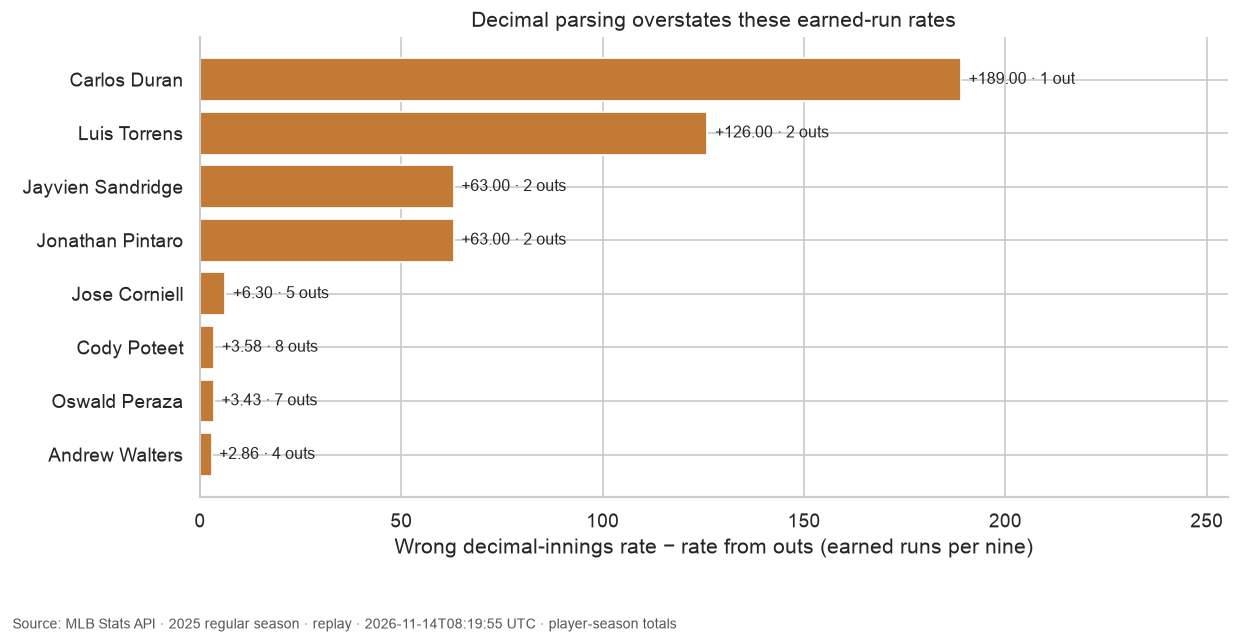

In [8]:
display(notation)
assert (
    con.execute(
        "SELECT count(*) FROM arithmetic WHERE innings_pitched IS NOT NULL AND (NOT regexp_full_match(innings_pitched,'[0-9]+[.][012]') OR notation_outs IS DISTINCT FROM outs)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM arithmetic WHERE reconstructed_era IS NOT NULL AND era IS NOT NULL AND abs(reconstructed_era-CAST(era AS DOUBLE))>.005000001"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute("SELECT count(*) FROM arithmetic WHERE outs=0 AND reconstructed_era IS NOT NULL").fetchone()[
        0
    ]
    == 0
)
assert (
    con.execute("SELECT count(*) FROM arithmetic WHERE wrong_decimal_era+1e-10<reconstructed_era").fetchone()[
        0
    ]
    == 0
)
largest = notation.iloc[0]
prose(
    f"The largest error in the full source pool is **{largest.error_runs_per_nine:.3f} earned runs per nine innings**, for **{largest.player_name}**: `{largest.innings_pitched}` represents **{int(largest.outs)} recorded out{'s' if largest.outs != 1 else ''}**. This is a denominator error, not a difference in scoring. The table deliberately shows the eight largest errors, including small workloads; it is not a player ranking. Reconstructed rates agree with available reported ERA values to rounding precision."
)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(notation.player_name, notation.error_runs_per_nine, color="#c27a35")
for i, r in enumerate(notation.itertuples()):
    ax.text(
        r.error_runs_per_nine + 0.01 * max(notation.error_runs_per_nine.max(), 1),
        i,
        f"+{r.error_runs_per_nine:.2f} · {r.outs} out{'s' if r.outs != 1 else ''}",
        va="center",
        fontsize=9,
    )
ax.invert_yaxis()
ax.set_xlim(0, max(notation.error_runs_per_nine.max(), 1) * 1.35)
ax.set(
    xlabel="Wrong decimal-innings rate − rate from outs (earned runs per nine)",
    title="Decimal parsing overstates these earned-run rates",
)
finish(fig)

## Change the comparison pool without changing anyone's statistics

The local minimum selects players with sufficient recorded workload for this demonstration. Order by the unrounded reconstructed rate, then by outs descending and player ID for deterministic ties. This is a descriptive table, with no uncertainty estimate, park adjustment, role adjustment or forecast.

For the selected population, `27 × sum(earned_runs) / sum(outs)` weights exposure by outs. The simple mean of player rates gives each player equal weight; they answer different questions. Neither is an official league ERA because this is a filtered player subset.

In [9]:
%%sql leaders <<
SELECT player_id,player_name,innings_pitched,outs,earned_runs,num_teams,
 reconstructed_era,era AS reported_era
FROM eligible ORDER BY reconstructed_era,outs DESC,player_id LIMIT 10;

In [10]:
%%sql rates <<
SELECT count(*) AS selected_players,sum(outs) AS selected_outs,
 sum(earned_runs) AS selected_earned_runs,
 27.0*sum(earned_runs)/nullif(sum(outs),0) AS exposure_weighted_rate,
 avg(reconstructed_era) AS unweighted_player_mean
FROM eligible;

,player_id,player_name,innings_pitched,outs,earned_runs,num_teams,reconstructed_era,reported_era
0,547973,Aroldis Chapman,61.1,184,8,1,1.173913,1.17
1,621242,Edwin Díaz,66.1,199,12,1,1.628141,1.63
2,682842,Abner Uribe,75.1,226,14,1,1.672566,1.67
3,543135,Nathan Eovaldi,130.0,390,25,1,1.730769,1.73
4,662253,Andrés Muñoz,62.1,187,12,1,1.732620,1.73
5,678495,Randy Rodríguez,50.2,152,10,1,1.776316,1.78
6,669432,Trevor Rogers,109.2,329,22,1,1.805471,1.81
7,592094,Jason Adam,65.1,196,14,1,1.928571,1.93
8,694335,Matt Svanson,60.1,181,13,1,1.939227,1.94
9,694973,Paul Skenes,187.2,563,41,1,1.966252,1.97


,selected_players,selected_outs,selected_earned_runs,exposure_weighted_rate,unweighted_player_mean
0,339,100610.0,14491.0,3.888848,3.848251


At **150 outs (50 innings)**, **339 of 873 players** remain. The first displayed row is **Aroldis Chapman**, with reconstructed rate **1.174** over **184 outs**. Selected-population exposure-weighted rate: **3.889**, versus equal-player mean **3.848** earned runs per nine. Eligibility changes the population; it does not alter any player's observed numerator or denominator.

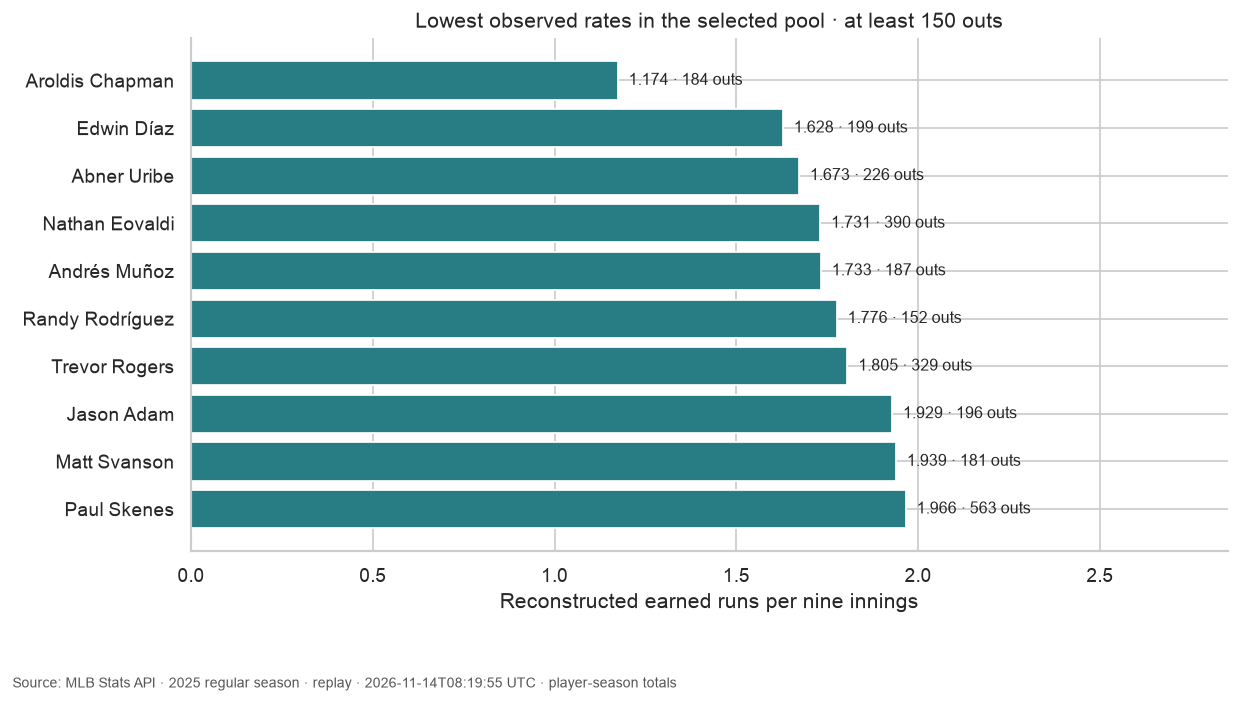

In [11]:
display(leaders)
display(rates)
assert int(rates.selected_players.iloc[0]) > 0
assert (
    con.execute(
        "SELECT count(*) FROM eligible WHERE outs<? OR reconstructed_era IS NULL", [MIN_OUTS]
    ).fetchone()[0]
    == 0
)
assert con.execute(
    "SELECT abs(sum(reconstructed_era*outs)/sum(outs)-27.0*sum(earned_runs)/sum(outs))<1e-10 FROM eligible"
).fetchone()[0]
r = rates.iloc[0]
winner = leaders.iloc[0]
prose(
    f"At **{MIN_OUTS} outs ({MIN_OUTS / 3:g} innings)**, **{int(r.selected_players)} of {int(diagnostics.player_rows.iloc[0])} players** remain. The first displayed row is **{winner.player_name}**, with reconstructed rate **{winner.reconstructed_era:.3f}** over **{int(winner.outs)} outs**. Selected-population exposure-weighted rate: **{r.exposure_weighted_rate:.3f}**, versus equal-player mean **{r.unweighted_player_mean:.3f}** earned runs per nine. Eligibility changes the population; it does not alter any player's observed numerator or denominator."
)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(leaders.player_name, leaders.reconstructed_era, color="#287d85")
for i, row in enumerate(leaders.itertuples()):
    ax.text(
        row.reconstructed_era + 0.03,
        i,
        f"{row.reconstructed_era:.3f} · {row.outs} outs",
        va="center",
        fontsize=9,
    )
ax.invert_yaxis()
ax.set_xlim(0, max(float(leaders.reconstructed_era.max()), 1) * 1.45)
ax.set(
    xlabel="Reconstructed earned runs per nine innings",
    title=f"Lowest observed rates in the selected pool · at least {MIN_OUTS} outs",
)
finish(fig)

## Experiment: require 150 innings instead of 50

Keep `DATA_MODE="replay"` and change only `MIN_OUTS` from **150 to 450**. Predict a smaller comparison pool, but do not predict the direction of its weighted rate: removing low-workload players can remove both high and low rates. Compare the count, named first row, top-ten chart and two pooled summaries.

The raw-data fingerprint, notation-error chart and all player-level rates must remain unchanged. Restore **150** afterwards. This experiment demonstrates selection sensitivity, not the superiority of either threshold or the reliability of a future-performance prediction.

In [12]:
con.close()
if replay:
    replay.close()
if previous_base is None:
    os.environ.pop("MLB_API_BASE_URL", None)
else:
    os.environ["MLB_API_BASE_URL"] = previous_base

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)